In [1]:
import matplotlib.patches as patches
import numpy as np
import matplotlib.pyplot as plt

class CapacitoresY:
    def __init__(self, m, n, d, horizontal_spacing, branches=3, top_extension=1.0, color='blue', ax=None):
        self.m = m  # number of strings (vertical)
        self.n = n  # number of capacitors in parallel (horizontal)
        self.d = d  # horizontal distance between capacitors
        self.horizontal_spacing = horizontal_spacing
        self.branches = branches  # number of Y branches
        self.top_extension = top_extension  # vertical line length from center upward
        self.color = color
        if ax is None:
            self.fig, self.ax = plt.subplots()
        else:
            self.ax = ax
            self.fig = ax.figure

    def draw_capacitor(self, x, y, color=None):
        color = color or self.color
        ax = self.ax

        plate_width = 1.5
        plate_height = 0.1
        spacing = 0.2

        top_plate = patches.Rectangle((x - plate_width / 2, y + spacing / 2),
                                      plate_width, plate_height,
                                      edgecolor=color, facecolor=color)
        bottom_plate = patches.Rectangle((x - plate_width / 2, y - plate_height - spacing / 2),
                                         plate_width, plate_height,
                                         edgecolor=color, facecolor=color)

        ax.add_patch(top_plate)
        ax.add_patch(bottom_plate)

        # Top and bottom wires
        ax.plot([x, x], [y - plate_height - spacing / 2, y - plate_height - spacing / 2 - 0.5], color=color, linewidth=1)
        ax.plot([x, x], [y + plate_height + spacing / 2, y + plate_height + spacing / 2 + 0.5], color=color, linewidth=1)

    def draw_parallel_capacitors(self, x, y, n, d, color=None):
        color = color or self.color
        for i in range(n):
            self.draw_capacitor(x + i * d, y, color)

        # Connecting lines (top and bottom)
        self.ax.plot([x, x + (n - 1) * d], [y + 0.75, y + 0.75], color=color, linewidth=1)
        self.ax.plot([x, x + (n - 1) * d], [y - 0.75, y - 0.75], color=color, linewidth=1)

    def draw_multiple_parallel_capacitors(self, x, y, n, d, m, vertical_spacing, color=None):
        color = color or self.color
        for i in range(m):
            self.draw_parallel_capacitors(x, y + i * vertical_spacing, n, d, color)
            if i > 0:
                center_x = x + (n - 1) * d / 2
                y1 = y + (i - 1) * vertical_spacing + 0.75
                y2 = y + i * vertical_spacing - 0.75
                self.ax.plot([center_x, center_x], [y1, y2], color=color, linewidth=1)

    def draw_bottom_connections(self, x1, x2, y, length):
        y_bottom = y - 0.75 - length
        self.ax.plot([x1, x1], [y - 0.75, y_bottom], color=self.color, linewidth=1)
        self.ax.plot([x2, x2], [y - 0.75, y_bottom], color=self.color, linewidth=1)
        self.ax.plot([x1, x2], [y_bottom, y_bottom], color=self.color, linewidth=1)
        self.xmed = (x1 + x2) / 2
        self.ymed = y_bottom

    def draw_top_connections(self, x, y, length):
        y_top = y + 0.75 + length
        self.ax.plot([x, x], [y + 0.75, y_top], color=self.color, linewidth=1)

    def draw(self, x_offset=0):
        m = self.m
        n = self.n
        d = self.d
        h = self.horizontal_spacing
        b = self.branches
        L = self.top_extension

        centers = []

        for i in range(b):
            x = x_offset + i * (n * d + h)
            self.draw_multiple_parallel_capacitors(x, 0, n, d, m, 4)
            x_center = x + (n - 1) * d / 2
            centers.append(x_center)

        # Bottom connections
        for i in range(len(centers) - 1):
            self.draw_bottom_connections(centers[i], centers[i + 1], 0, 2)

        # Top connections
        y_top = (m - 1) * 4
        for x in centers:
            self.draw_top_connections(x, y_top, 2)

        # Horizontal line at top
        y_line = y_top + 0.75 + 2
        x_start = centers[0]
        x_end = centers[-1]
        self.ax.plot([x_start, x_end], [y_line, y_line], color=self.color, linewidth=1)

        # Vertical extension from center
        x_center = (x_start + x_end) / 2
        self.ax.plot([x_center, x_center], [y_line, y_line + L], color=self.color, linewidth=1)

        return [self.xmed, self.ymed]

    @staticmethod
    def show_plot(xlim=None, ylim=None):
        plt.gca()
        if xlim is not None:
            plt.xlim(xlim)
        if ylim is not None:
            plt.ylim(ylim)
        plt.axis('off')
        plt.show()

    @staticmethod
    def generate_and_save_capacitor_plot(m=4, n=5, d=2.5, horizontal_spacing=6, branches=3,
                                         top_extension=1.0, filename='capacitores.png'):
        fig, ax = plt.subplots()
        ax.axis('off')
        fig.patch.set_facecolor('none')

        capacitores = CapacitoresY(m=m, n=n, d=d, horizontal_spacing=horizontal_spacing,
                                   branches=branches, top_extension=top_extension, color='red', ax=ax)
        capacitores.draw()

        # opcional: salvar imagem
        # plt.savefig(filename, dpi=300, bbox_inches='tight')

        return fig

In [2]:
import matplotlib.pyplot as plt

class CapacitoresYPlot:
    def __init__(self, params1, params2, figsize=(12, 6)):
        self.params1 = params1
        self.params2 = params2
        self.figsize = figsize

    def create_plot(self):
        # Create figure and two subplots
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=self.figsize)

        # Draw first capacitor bank
        bank1 = CapacitoresY(ax=ax1, **self.params1)
        bank1.draw()
        ax1.axis('off')

        # Draw second capacitor bank
        bank2 = CapacitoresY(ax=ax2, **self.params2)
        bank2.draw()
        ax2.axis('off')

        # Fix axes positions before computing transforms
        plt.tight_layout()
        fig.canvas.draw()

        # --- compute the bottom‐line Y (same in both) ---
        # from draw_bottom_connections: y_bottom = y - 0.75 - length
        # here y=0, length=2 → y_bottom = -2.75
        y_bottom = -0.75 - 2

        # --- compute X extremes in DATA coords ---
        b1 = self.params1['branches']
        n1 = self.params1['n']
        d1 = self.params1['d']
        h1 = self.params1['horizontal_spacing']
        # rightmost branch center of bank1
        x1_extreme = (b1 - 1)*(n1*d1 + h1) + (n1 - 1)*d1/2

        n2 = self.params2['n']
        d2 = self.params2['d']
        # leftmost branch center of bank2
        x2_extreme = (n2 - 1)*d2/2

        # --- transform to FIGURE coords ---
        start_disp = ax1.transData.transform((x1_extreme, y_bottom))
        end_disp   = ax2.transData.transform((x2_extreme, y_bottom))
        inv_fig    = fig.transFigure.inverted()
        start_fig  = inv_fig.transform(start_disp)
        end_fig    = inv_fig.transform(end_disp)

        # --- draw the black connector ---
        connector = plt.Line2D(
            [start_fig[0], end_fig[0]],
            [start_fig[1], end_fig[1]],
            transform=fig.transFigure,
            color='black',
            linewidth=2
        )
        fig.add_artist(connector)

        plt.show()




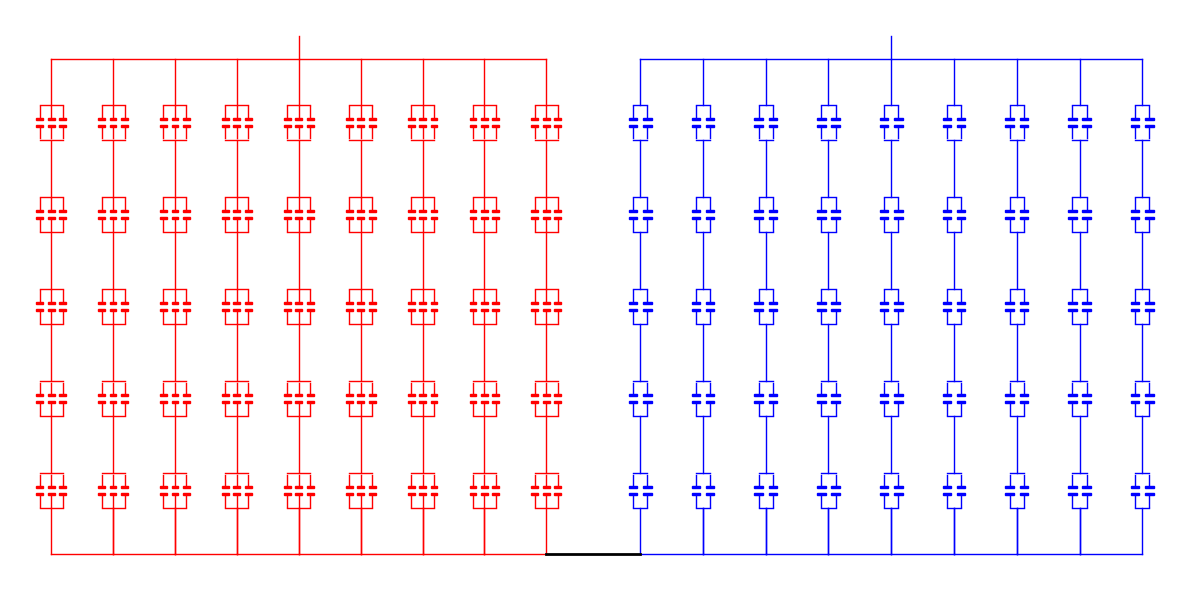

In [3]:
# Define parameters for each plot
params1 = {
    'm': 5,
    'n': 3,
    'd': 2.5,
    'horizontal_spacing': 6,
    'branches': 9,
    'top_extension': 1.0,
    'color': 'red'
}

params2 = {
    'm': 5,
    'n': 2,
    'd': 2.5,
    'horizontal_spacing': 6,
    'branches': 9,
    'top_extension': 1.0,
    'color': 'blue'
}

# Create and display the plot
plotter = CapacitoresYPlot(params1, params2)
plotter.create_plot()
